In [3]:
import matplotlib.pyplot as plt
import numpy as np
from neural_recording_chain.frozen_noise import make_frozen_noise
from neural_recording_chain.pyramidal_cell import simulate_pyramidal_cell
from neural_recording_chain.spikes import find_spikes
from neural_recording_chain.electrode import extracellular_potential
from neural_recording_chain.noise import thermal_noise_uV
from neural_recording_chain.noise import background_noise_uV
from neural_recording_chain.detector import detect_spikes

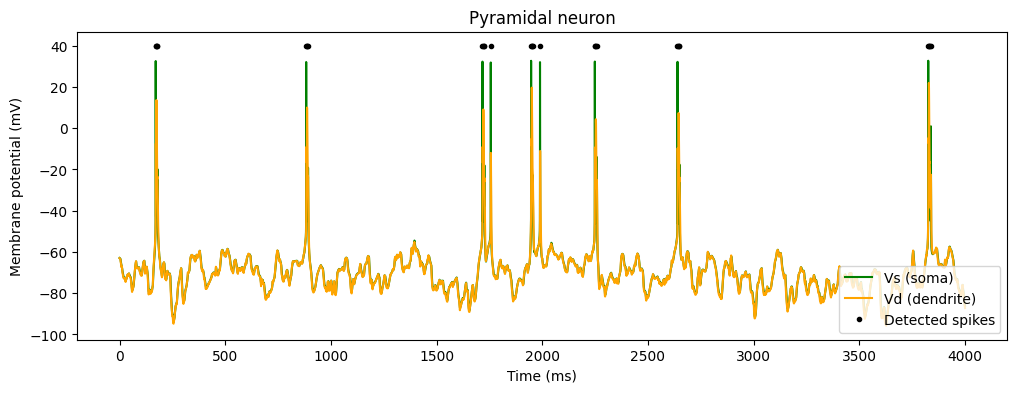

In [ ]:

input_theory, hidden_state = make_frozen_noise(duration_ms=4000, dt_ms=0.05, seed=0)
result = simulate_pyramidal_cell(input_theory, dt_ms=0.05)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(result["time_ms"], result["v_soma_mV"], color="green", label="Vs (soma)")
ax.plot(result["time_ms"], result["v_dend_mV"], color="orange", label="Vd (dendrite)")
ax.plot(result["spike_times_ms"], [40] * len(result["spike_times_ms"]), "k.", label="Detected spikes")
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Membrane potential (mV)")
ax.set_title("Pyramidal neuron")
ax.legend(loc="lower right")
plt.show()

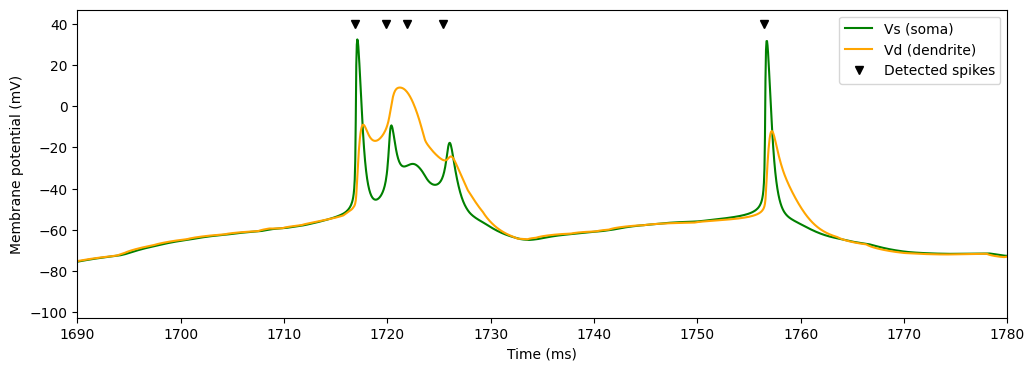

In [2]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(result["time_ms"], result["v_soma_mV"], color="green", label="Vs (soma)")
ax.plot(result["time_ms"], result["v_dend_mV"], color="orange", label="Vd (dendrite)")
ax.plot(result["spike_times_ms"], [40] * len(result["spike_times_ms"]), "kv", label="Detected spikes")
ax.set_xlim(1690, 1780)
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Membrane potential (mV)")
ax.legend(loc="upper right")
plt.show()

In [ ]:

spike_times, spike_heights = find_spikes(result["v_soma_mV"], result["time_ms"])
print("old counter:", len(result["spike_times_ms"]))
print("new finder: ", len(spike_times))

in_window = (spike_times > 1690) & (spike_times < 1780)
print(spike_times[in_window].round(1))
print(spike_heights[in_window].round(1))

old counter: 31
new finder:  24
[1717.1 1720.4 1726.  1756.8]
[ 32.4  -9.3 -17.7  31.6]


lowest:  -288.5 uV
highest: 186.5 uV


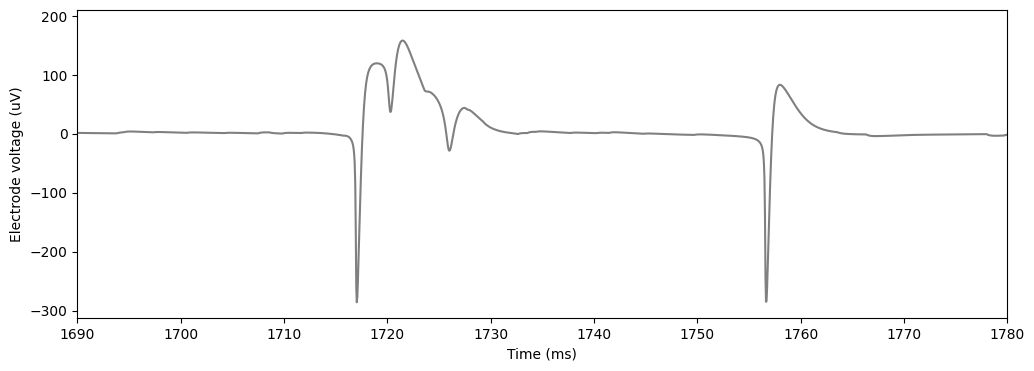

In [ ]:

v_electrode_uV = extracellular_potential(result["v_soma_mV"], result["v_dend_mV"])
print("lowest: ", v_electrode_uV.min().round(1), "uV")
print("highest:", v_electrode_uV.max().round(1), "uV")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(result["time_ms"], v_electrode_uV, color="grey")
ax.set_xlim(1690, 1780)
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Electrode voltage (uV)")
plt.show()

noise size: 13.1 uV


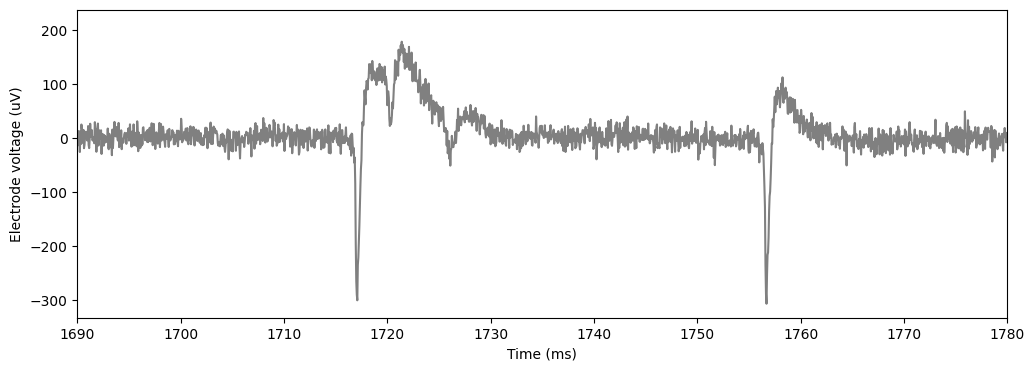

In [ ]:

noise = thermal_noise_uV(len(v_electrode_uV), dt_ms=0.05)
print("noise size:", noise.std().round(1), "uV")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(result["time_ms"], v_electrode_uV + noise, color="grey")
ax.set_xlim(1690, 1780)
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Electrode voltage (uV)")
plt.show()

hum size:   10.0 uV
total noise: 16.5 uV


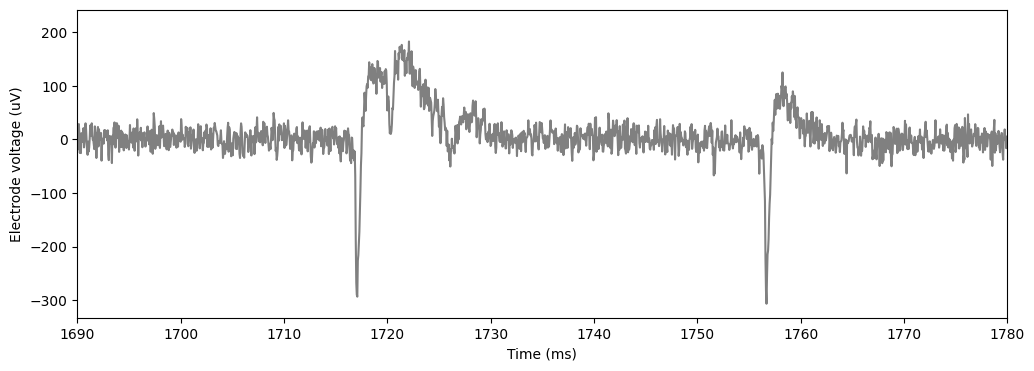

In [ ]:

hum = background_noise_uV(len(v_electrode_uV), dt_ms=0.05)
recording_uV = v_electrode_uV + noise + hum
print("hum size:  ", hum.std().round(1), "uV")
print("total noise:", (noise + hum).std().round(1), "uV")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(result["time_ms"], recording_uV, color="grey")
ax.set_xlim(1690, 1780)
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Electrode voltage (uV)")
plt.show()

threshold: 77.0 uV
true spikes: 24
detected:    12


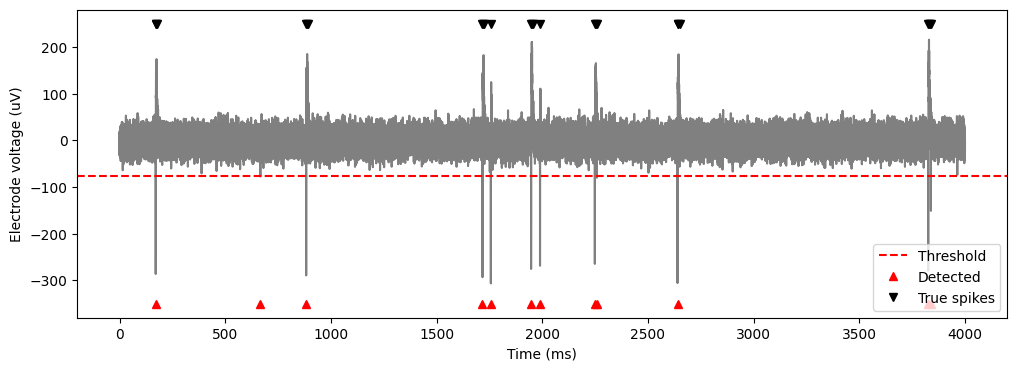

In [ ]:

detected_times, threshold_uV = detect_spikes(recording_uV, result["time_ms"])
print("threshold:", threshold_uV.round(1), "uV")
print("true spikes:", len(spike_times))
print("detected:   ", len(detected_times))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(result["time_ms"], recording_uV, color="grey")
ax.axhline(-threshold_uV, color="red", linestyle="--", label="Threshold")
ax.plot(detected_times, [-350] * len(detected_times), "r^", label="Detected")
ax.plot(spike_times, [250] * len(spike_times), "kv", label="True spikes")
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Electrode voltage (uV)")
ax.legend(loc="lower right")
plt.show()

In [ ]:
from neural_recording_chain.scoring import score_detection

hits, misses, false_alarms = score_detection(spike_times, detected_times)
print("hits:", hits)
print("misses:", misses)
print("false alarms:", false_alarms)

hits:         11
misses:       13
false alarms: 1


In [ ]:
# Euler step check: the same 10 s of input, simulated with 0.05 ms and 0.025 ms steps
input_theory, hidden_state = make_frozen_noise(duration_ms=10000, dt_ms=0.05, seed=0)

# the same input for the smaller step: each value repeated twice
input_half_step = np.repeat(input_theory, 2)

step_sizes = [0.05, 0.025]
inputs = [input_theory, input_half_step]

for k in range(2):
    result = simulate_pyramidal_cell(inputs[k], dt_ms=step_sizes[k])
    spike_times, spike_heights = find_spikes(result["v_soma_mV"], result["time_ms"])
    event_times, event_types = classify_events(result["v_soma_mV"], result["v_dend_mV"], result["time_ms"])

    print("step", step_sizes[k], "ms | spikes:", len(spike_times), "| events:", len(event_times),
          "| bursts:", event_types.count("burst"), "| singles:", event_types.count("single"))
    print("  first five event times (ms):", np.round(event_times[:5], 2))